<a href="https://colab.research.google.com/github/smruthi215/DLG--LAB/blob/main/1BM24CD063_SmruthiN_Program_6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Bidirectional, Dense, TimeDistributed
from tensorflow.keras.optimizers import Adam

np.random.seed(7)
tf.random.set_seed(7)

num_notes = 40
sequence_length = 25
num_sequences = 1200

data = np.random.randint(0, num_notes,
                         size=(num_sequences, sequence_length))

print("Data shape:", data.shape)

Data shape: (1200, 25)


In [2]:
x_train = data[:, :-1]
y_train = data[:, 1:]

x_train = to_categorical(x_train, num_classes=40)
y_train = to_categorical(y_train, num_classes=40)

print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)

x_train shape: (1200, 24, 40)
y_train shape: (1200, 24, 40)


In [3]:
model = Sequential([
    Input(shape=(24, 40)),

    Bidirectional(LSTM(100, return_sequences=True)),

    Bidirectional(LSTM(100, return_sequences=True)),

    TimeDistributed(Dense(40, activation='softmax'))
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ bidirectional (Bidirectional)   │ (None, 24, 200)        │       112,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional_1 (Bidirectional) │ (None, 24, 200)        │       240,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ time_distributed                │ (None, 24, 40)         │         8,040 │
│ (TimeDistributed)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 361,640 (1.38 MB)

 Trainable params: 361,640 (1.38 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history = model.fit(
    x_train,
    y_train,
    epochs=15,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 11s 363ms/step - accuracy: 0.0959 - loss: 3.6597 - val_accuracy: 0.1606 - val_loss: 3.6180
Epoch 2/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 237ms/step - accuracy: 0.1414 - loss: 3.5382 - val_accuracy: 0.1226 - val_loss: 3.4123
Epoch 3/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 158ms/step - accuracy: 0.1419 - loss: 3.2691 - val_accuracy: 0.1597 - val_loss: 3.1227
Epoch 4/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 274ms/step - accuracy: 0.1843 - loss: 2.9697 - val_accuracy: 0.2052 - val_loss: 2.8199
Epoch 5/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 153ms/step - accuracy: 0.2388 - loss: 2.6238 - val_accuracy: 0.2714 - val_loss: 2.4509
Epoch 6/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 154ms/step - accuracy: 0.3102 - loss: 2.2466 - val_accuracy: 0.3455 - val_loss: 2.0917
Epoch 7/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 164ms/step - accuracy: 0.3918 - loss: 1.8834 - val_accuracy: 0.4293 - val_loss: 1.7591
Epoch 8/15
15/15 ━━━━━━━━━━━━━━━━━━━━ 5s 321ms/step - accuracy: 0.4878 - loss: 1.5550 - val_accuracy: 0

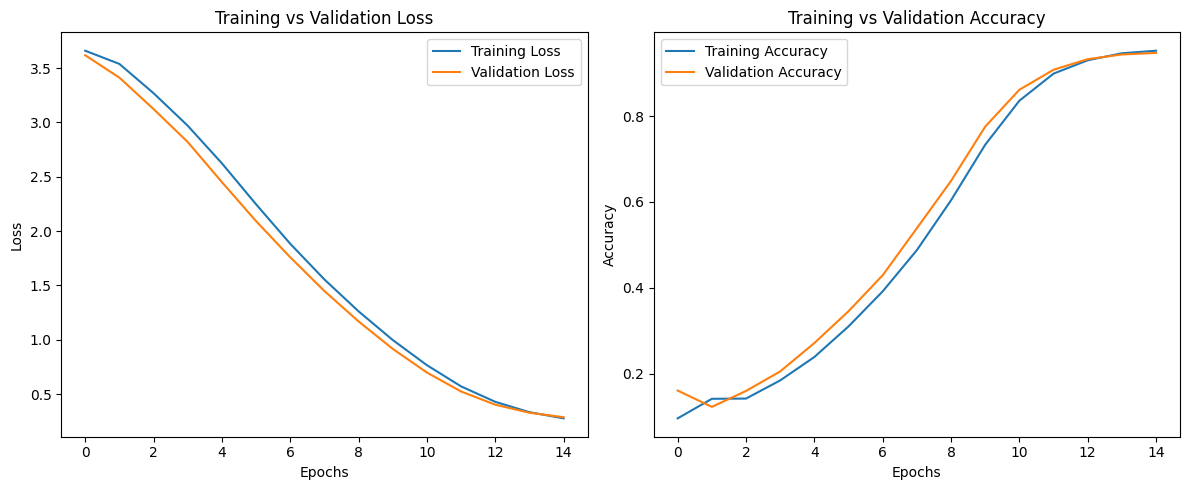

In [5]:
plt.figure(figsize=(12, 5))

# Loss plot
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Training vs Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()

# Accuracy plot
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training vs Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()

plt.tight_layout()
plt.show()

In [6]:
def generate_music(model, start_sequence, num_generated_notes=40):

    current = start_sequence.copy()
    generated = []

    for i in range(num_generated_notes):

        pred = model.predict(current, verbose=0)

        next_note = np.argmax(pred[:, -1, :], axis=-1)

        generated.append(int(next_note[0]))

        new_note_one_hot = to_categorical(
            next_note, num_classes=40
        ).reshape(1, 1, 40)

        current = np.concatenate(
            [current[:, 1:, :], new_note_one_hot],
            axis=1
        )

    return generated


# Random starting sequence
start_sequence = np.random.randint(0, 40, size=(1, 24))

start_sequence = to_categorical(
    start_sequence, num_classes=40
)

# Generate music
generated_notes = generate_music(
    model, start_sequence, num_generated_notes=40
)

print("Generated notes:", generated_notes)

Generated notes: [26, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10, 10]


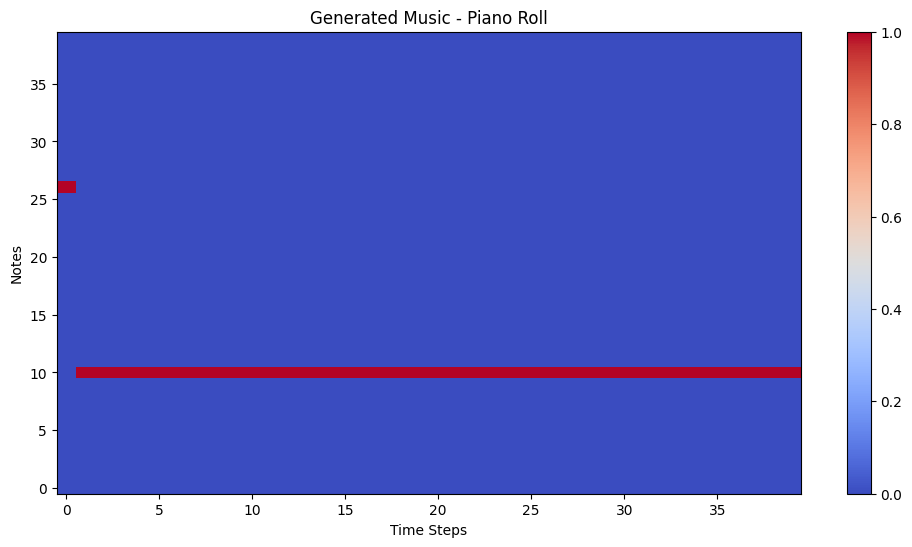

In [7]:
piano_roll = np.zeros((40, 40))

for t, note in enumerate(generated_notes):
    piano_roll[note, t] = 1

plt.figure(figsize=(12, 6))

plt.imshow(
    piano_roll,
    aspect='auto',
    cmap='coolwarm',
    origin='lower'
)

plt.title('Generated Music - Piano Roll')
plt.xlabel('Time Steps')
plt.ylabel('Notes')

plt.colorbar()
plt.show()